# 08 · Hidden Markov Model: Inferring Activity-State Sequences
**Group 10: Sequential Human Activity Recognition** — Markov models, HMM, forward-backward, Viterbi

**Task:** treat the activity performed in each window as a **hidden state**. We only observe accelerometer-derived
features. We fit a Gaussian HMM (Baum–Welch/EM), then use the **forward–backward algorithm** to get the probability
of each state at each time step, and the **Viterbi algorithm** to decode the single most likely activity sequence —
then check both against the true (labelled) activities, which are used only for evaluation, never for fitting.

We also hand-implement forward–backward and Viterbi from the model's own parameters, to show the mechanics behind
`hmmlearn`'s `predict_proba` / `predict`.

In [1]:
# --- Colab-friendly setup: installs, paths, dataset download, plot helpers (no repo dependency) ---
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hmmlearn"], check=False)

import os, json, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

RAW, PROCESSED, FIGURES, MODELS = Path("data/raw"), Path("data/processed"), Path("outputs/figures"), Path("outputs/models")
for d in (RAW, PROCESSED, FIGURES, MODELS):
    d.mkdir(parents=True, exist_ok=True)

HAR = RAW / "har" / "UCI HAR Dataset"
if not HAR.exists():
    url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
    zpath = RAW / "har.zip"
    urllib.request.urlretrieve(url, zpath)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(RAW / "har")
    with zipfile.ZipFile(RAW / "har" / "UCI HAR Dataset.zip") as z:
        z.extractall(RAW / "har")
    print("Downloaded and extracted UCI HAR Dataset")

BLUE, ORANGE = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#ffffff"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("div_blue_red", ["#104281", "#3987e5", "#9ec5f4", "#f0efec", "#f2a3a2", "#e34948", "#9e2323"])

def set_style():
    mpl.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "semibold",
        "axes.titlelocation": "left", "axes.titlepad": 12, "axes.labelsize": 11, "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
        "text.color": INK, "legend.frameon": False, "legend.fontsize": 10, "lines.linewidth": 2,
        "axes.prop_cycle": mpl.cycler(color=SERIES),
    })

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()

def save_json(obj, name):
    (MODELS / f"{name}.json").write_text(json.dumps(obj, indent=2, default=float))

set_style()

from scipy.stats import multivariate_normal
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, adjusted_rand_score, accuracy_score
from scipy.optimize import linear_sum_assignment
from hmmlearn.hmm import GaussianHMM

SEED = 42
feat = pd.read_csv(PROCESSED / "har_features.csv")
feat["row"] = np.arange(len(feat))           # original row order (train file, then test file)
FEATS = ["mean_mag", "std_mag", "energy", "mean_x", "mean_y", "mean_z", "std_x", "std_y", "std_z", "jerk_energy"]
print(feat.shape, "subjects:", feat.subject.nunique(), "activities:", feat.activity.nunique())


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /Users/ompathania/Desktop/ML_Project_5th_sem/code/.venv/bin/python -m pip install --upgrade pip


(10299, 14) subjects: 30 activities: 6


## 1. Build one continuous observation sequence per subject
An HMM needs ordered sequences. Windows already come in subject order with 50% overlap, so within each subject the
row order *is* the time order. `hmmlearn` fits on several sequences at once via `lengths`.

In [2]:
feat = feat.sort_values(["subject"], kind="stable").reset_index(drop=True)      # already time-ordered within each subject
lengths = feat.groupby("subject").size().values
X_raw = feat[FEATS].values
scaler = StandardScaler().fit(X_raw)
X = scaler.transform(X_raw)
y_true = feat["activity_id"].values
print("Sequences (subjects):", len(lengths), "| total windows:", len(X))

# Train/test by subject (first 24 subjects train, last 6 test) — never mix windows of the same subject across sets
subjects = feat.subject.unique()
train_subj, test_subj = subjects[:24], subjects[24:]
tr_mask, te_mask = feat.subject.isin(train_subj).values, feat.subject.isin(test_subj).values
X_tr, X_te = X[tr_mask], X[te_mask]
len_tr = feat[tr_mask].groupby("subject").size().values
len_te = feat[te_mask].groupby("subject").size().values
print(f"Train: {tr_mask.sum()} windows / {len(train_subj)} subjects | Test: {te_mask.sum()} windows / {len(test_subj)} subjects")

Sequences (subjects): 30 | total windows: 10299
Train: 8013 windows / 24 subjects | Test: 2286 windows / 6 subjects


## 2. Fit the Gaussian HMM (unsupervised — labels not used for training)
6 hidden states (matching the 6 true activities), full covariance, Baum–Welch (EM), best of several random restarts.

In [3]:
N = 6
best, best_ll = None, -np.inf
for s in range(8):
    m = GaussianHMM(n_components=N, covariance_type="full", n_iter=300, tol=1e-4, random_state=s)
    m.fit(X_tr, lengths=len_tr)
    if m.monitor_.converged and m.score(X_tr, lengths=len_tr) > best_ll:
        best, best_ll = m, m.score(X_tr, lengths=len_tr)
model = best
print("Converged:", model.monitor_.converged, "| Train log-likelihood:", round(best_ll, 1))

Model is not converging.  Current: 84888.99036911225 is not greater than 84889.04226709533. Delta is -0.05189798308128957


Model is not converging.  Current: 83305.94567770796 is not greater than 83305.94730958012. Delta is -0.0016318721609422937


Model is not converging.  Current: 83486.30021953394 is not greater than 83486.41054923792. Delta is -0.11032970398082398


Model is not converging.  Current: 84811.65584218715 is not greater than 84811.79877119687. Delta is -0.14292900972941425


Converged: True | Train log-likelihood: 84888.9


## 3. Forward–backward: state probabilities at every time step
`predict_proba` runs forward–backward internally. We also hand-code it from `model.startprob_`, `model.transmat_`
and the Gaussian emissions, and confirm it matches `hmmlearn` exactly.

In [4]:
def forward_backward(m, Xs):
    B = np.column_stack([multivariate_normal(m.means_[k], m.covars_[k]).pdf(Xs) for k in range(m.n_components)])
    T = len(Xs)
    alpha = np.zeros((T, m.n_components)); c = np.zeros(T)
    alpha[0] = m.startprob_ * B[0]; c[0] = alpha[0].sum(); alpha[0] /= c[0]
    for t in range(1, T):
        alpha[t] = (alpha[t - 1] @ m.transmat_) * B[t]; c[t] = alpha[t].sum(); alpha[t] /= c[t]
    beta = np.zeros((T, m.n_components)); beta[-1] = 1
    for t in range(T - 2, -1, -1):
        beta[t] = (m.transmat_ @ (B[t + 1] * beta[t + 1])) / c[t + 1]
    gamma = alpha * beta
    return gamma / gamma.sum(axis=1, keepdims=True)

te_feat = feat[te_mask].reset_index(drop=True)
first_subj_len = len_te[0]
X_s0 = X_te[:first_subj_len]
gamma_manual = forward_backward(model, X_s0)
gamma_lib = model.predict_proba(X_s0)
print("Max |manual − hmmlearn| posterior difference:", np.abs(gamma_manual - gamma_lib).max())

Max |manual − hmmlearn| posterior difference: 1.4875489728893854e-10


## 4. Viterbi: the single most likely state sequence
Decoded independently per test subject (states never carry over between people).

In [5]:
def viterbi(m, Xs):
    B = np.column_stack([multivariate_normal(m.means_[k], m.covars_[k]).logpdf(Xs) for k in range(m.n_components)])
    T, K = B.shape
    logA, logpi = np.log(m.transmat_ + 1e-300), np.log(m.startprob_ + 1e-300)
    delta = np.zeros((T, K)); psi = np.zeros((T, K), dtype=int)
    delta[0] = logpi + B[0]
    for t in range(1, T):
        scores = delta[t - 1][:, None] + logA
        psi[t] = scores.argmax(axis=0); delta[t] = scores.max(axis=0) + B[t]
    path = np.zeros(T, dtype=int); path[-1] = delta[-1].argmax()
    for t in range(T - 2, -1, -1):
        path[t] = psi[t + 1, path[t + 1]]
    return path

path_manual = viterbi(model, X_s0)
path_lib = model.predict(X_s0)
print("Manual Viterbi matches hmmlearn.predict exactly:", np.array_equal(path_manual, path_lib))

# Decode every test subject
decoded = np.concatenate([model.predict(X_te[sum(len_te[:i]):sum(len_te[:i + 1])]) for i in range(len(len_te))])
posteriors = np.concatenate([model.predict_proba(X_te[sum(len_te[:i]):sum(len_te[:i + 1])]) for i in range(len(len_te))])

Manual Viterbi matches hmmlearn.predict exactly: True


## 5. Evaluation: map hidden states → true activities (Hungarian algorithm), then score
The HMM's state indices are arbitrary labels, so we find the best one-to-one mapping to true activities on the
*training* assignment, then apply it to the held-out test subjects.

In [6]:
ACT = pd.read_csv(RAW / "har" / "UCI HAR Dataset" / "activity_labels.txt", sep=r"\s+", header=None, names=["id", "activity"])
ACT_MAP = dict(zip(ACT.id, ACT.activity))
train_decoded = np.concatenate([model.predict(X_tr[sum(len_tr[:i]):sum(len_tr[:i + 1])]) for i in range(len(len_tr))])
y_tr_true = feat[tr_mask]["activity_id"].values
cost = -confusion_matrix(y_tr_true - 1, train_decoded, labels=range(6))
row, col = linear_sum_assignment(cost)
state_to_activity = {s: a + 1 for a, s in zip(row, col)}     # +1: activity ids are 1..6
print("Learned state → activity mapping:", {k: ACT_MAP[v] for k, v in state_to_activity.items()})

y_te_true = te_feat["activity_id"].values
y_pred = np.vectorize(state_to_activity.get)(decoded)
acc = accuracy_score(y_te_true, y_pred)
ari = adjusted_rand_score(y_te_true, decoded)
print(f"Test accuracy (after state→activity mapping): {acc:.3f} | ARI (mapping-free): {ari:.3f}")

Learned state → activity mapping: {np.int64(3): 'WALKING', np.int64(4): 'WALKING_UPSTAIRS', np.int64(0): 'WALKING_DOWNSTAIRS', np.int64(5): 'SITTING', np.int64(1): 'STANDING', np.int64(2): 'LAYING'}
Test accuracy (after state→activity mapping): 0.598 | ARI (mapping-free): 0.485


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


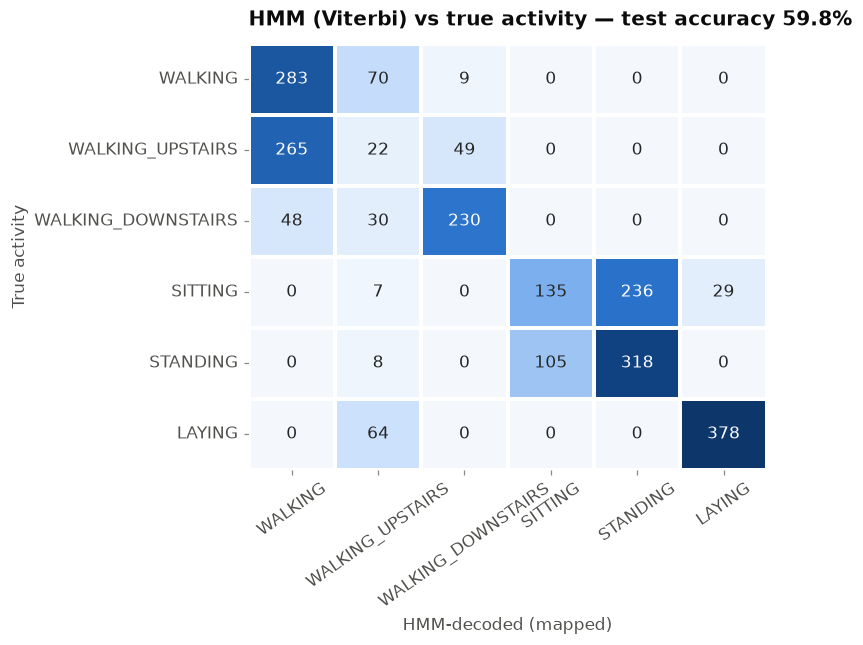

In [7]:
cm = confusion_matrix(y_te_true, y_pred, labels=range(1, 7))
fig, ax = plt.subplots(figsize=(7.2, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap=SEQ_BLUE, cbar=False, linewidths=1.5, linecolor=SURFACE,
            xticklabels=[ACT_MAP[i] for i in range(1, 7)], yticklabels=[ACT_MAP[i] for i in range(1, 7)], ax=ax)
ax.set(title=f"HMM (Viterbi) vs true activity — test accuracy {acc:.1%}",
       xlabel="HMM-decoded (mapped)", ylabel="True activity")
ax.tick_params(axis="x", rotation=35); ax.tick_params(axis="y", rotation=0)
save(fig, "har_confusion_matrix")

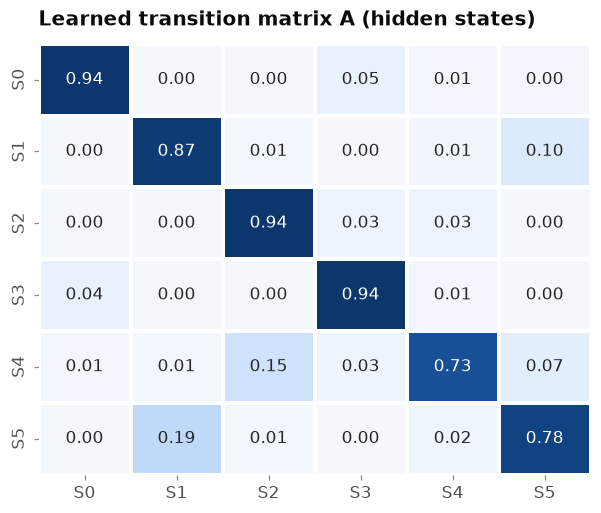

In [8]:
fig, ax = plt.subplots(figsize=(5.6, 4.8))
sns.heatmap(model.transmat_, annot=True, fmt=".2f", cmap=SEQ_BLUE, cbar=False, linewidths=1.5, linecolor=SURFACE,
            xticklabels=[f"S{i}" for i in range(N)], yticklabels=[f"S{i}" for i in range(N)], ax=ax)
ax.set(title="Learned transition matrix A (hidden states)")
save(fig, "har_transition_matrix")

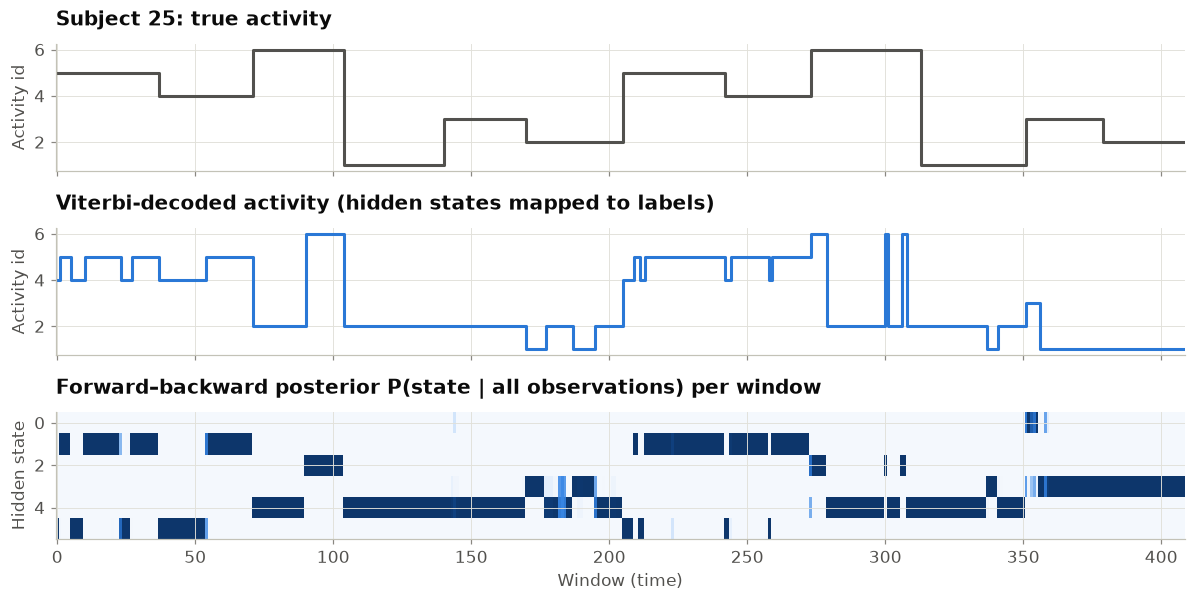

In [9]:
s0_true = te_feat[te_feat.subject == test_subj[0]]["activity_id"].values
fig, axes = plt.subplots(3, 1, figsize=(11, 5.6), sharex=True)
axes[0].step(range(len(s0_true)), s0_true, color=INK_2, where="post")
axes[0].set(title=f"Subject {test_subj[0]}: true activity", ylabel="Activity id")
axes[1].step(range(len(path_lib)), [state_to_activity[s] for s in path_lib], color=BLUE, where="post")
axes[1].set(title="Viterbi-decoded activity (hidden states mapped to labels)", ylabel="Activity id")
im = axes[2].imshow(gamma_lib.T, aspect="auto", cmap=SEQ_BLUE, interpolation="nearest")
axes[2].set(title="Forward–backward posterior P(state | all observations) per window", ylabel="Hidden state",
            xlabel="Window (time)")
save(fig, "har_decoded_timeline")

## 6. Clustering baselines: K-Means and Gaussian Mixture (same features, no time information)
Clustering groups windows by feature similarity only; it ignores the order of windows. Comparing it with the HMM shows
how much the **Markov transition structure** adds. Cluster ids are mapped to activities the same way (Hungarian, train only).

In [10]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

def map_labels(train_labels, test_labels):
    r, c = linear_sum_assignment(-confusion_matrix(y_tr_true - 1, train_labels, labels=range(6)))
    mp = {s: a + 1 for a, s in zip(r, c)}
    return np.array([mp[s] for s in test_labels])

def avg_segment_length(labels, lens):
    out, start = [], 0
    for L in lens:
        seg = labels[start:start + L]; start += L
        out.append(L / np.r_[True, seg[1:] != seg[:-1]].sum())
    return float(np.mean(out))

km = KMeans(n_clusters=6, n_init=10, random_state=SEED).fit(X_tr)
gm = GaussianMixture(n_components=6, covariance_type="full", n_init=5, random_state=SEED).fit(X_tr)
rows = []
for name, tr_lab, te_lab in [("K-Means", km.predict(X_tr), km.predict(X_te)),
                             ("Gaussian Mixture", gm.predict(X_tr), gm.predict(X_te)),
                             ("Gaussian HMM (Viterbi)", train_decoded, decoded)]:
    pred = map_labels(tr_lab, te_lab)
    rows.append({"Model": name, "Test accuracy": accuracy_score(y_te_true, pred),
                 "ARI": adjusted_rand_score(y_te_true, te_lab), "Silhouette": silhouette_score(X_te, te_lab),
                 "Avg segment length (windows)": avg_segment_length(te_lab, len_te)})
rows.append({"Model": "True activities", "Test accuracy": 1.0, "ARI": 1.0,
             "Silhouette": silhouette_score(X_te, y_te_true), "Avg segment length (windows)": avg_segment_length(y_te_true, len_te)})
cmp = pd.DataFrame(rows)
cmp.to_csv(MODELS / "har_model_comparison.csv", index=False)
cmp.round(3)

,Model,Test accuracy,ARI,Silhouette,Avg segment length (windows)
0,K-Means,0.570,0.464,0.412,7.786
1,Gaussian Mixture,0.612,0.486,0.357,11.119
2,Gaussian HMM (Viterbi),0.598,0.485,0.266,11.729
3,True activities,1.000,1.000,0.257,29.454


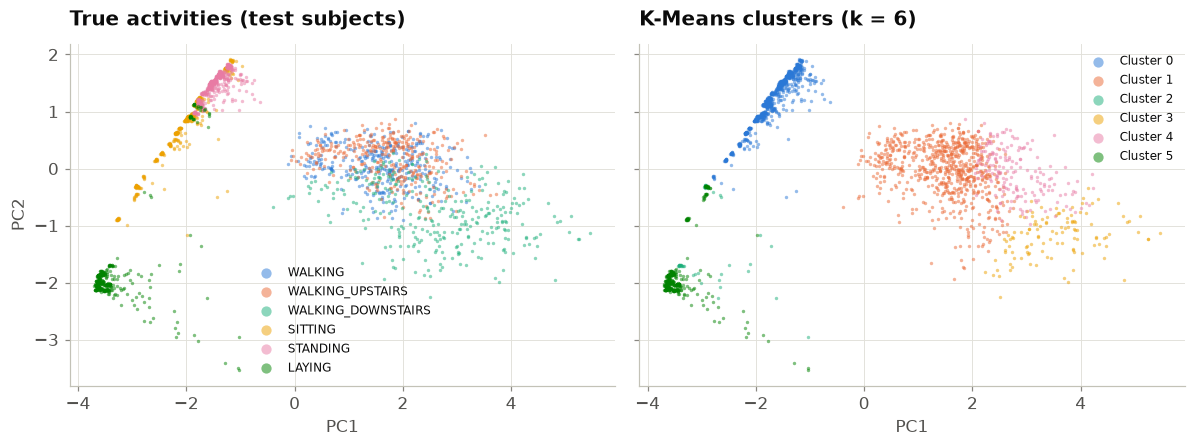

In [11]:
P = PCA(n_components=2, random_state=SEED).fit(X_tr)
Z = P.transform(X_te)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, lab, t in [(axes[0], y_te_true - 1, "True activities (test subjects)"), (axes[1], km.predict(X_te), "K-Means clusters (k = 6)")]:
    for c in range(6):
        m = lab == c
        ax.scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.5, color=SERIES[c], linewidths=0,
                   label=ACT_MAP[c + 1] if ax is axes[0] else f"Cluster {c}")
    ax.set(title=t, xlabel="PC1")
    ax.legend(markerscale=3, fontsize=8)
axes[0].set_ylabel("PC2")
save(fig, "har_pca_clusters")

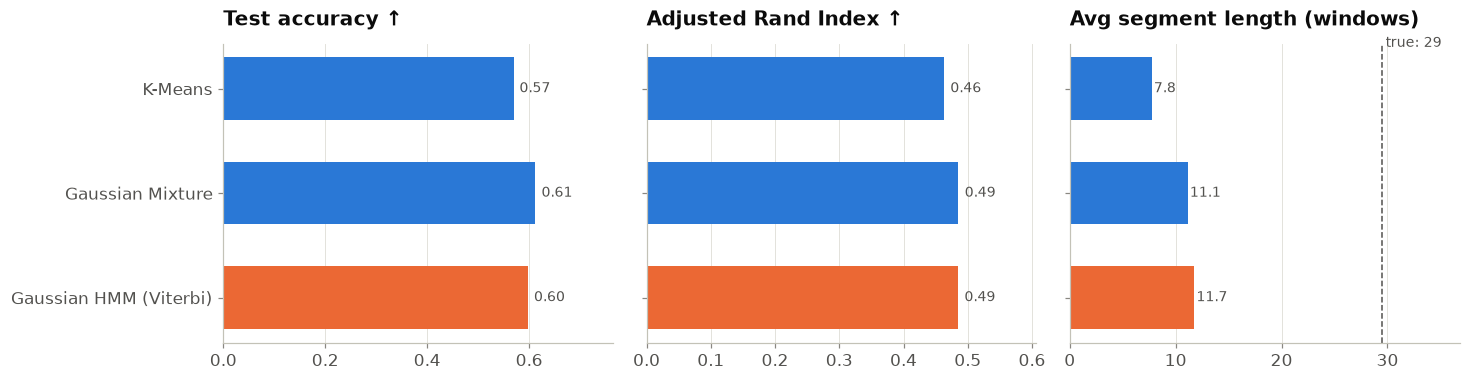

In [12]:
m3 = cmp[cmp.Model != "True activities"].reset_index(drop=True)
true_len = cmp.loc[cmp.Model == "True activities", "Avg segment length (windows)"].iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6), sharey=True)
colors = [SERIES[1] if "HMM" in m else SERIES[0] for m in m3.Model]
for ax, col, title, fmt in [(axes[0], "Test accuracy", "Test accuracy ↑", "{:.2f}"), (axes[1], "ARI", "Adjusted Rand Index ↑", "{:.2f}"),
                            (axes[2], "Avg segment length (windows)", "Avg segment length (windows)", "{:.1f}")]:
    ax.barh(m3.Model[::-1], m3[col][::-1], color=colors[::-1], height=0.6)
    for yv, v in enumerate(m3[col][::-1]):
        ax.text(v * 1.02, yv, fmt.format(v), va="center", fontsize=9, color=INK_2)
    ax.set(title=title, xlim=(0, max(m3[col].max(), true_len if "segment" in col else 0) * 1.25))
    ax.grid(axis="y", visible=False)
axes[2].axvline(true_len, color=INK_2, ls="--", lw=1)
axes[2].text(true_len, 2.4, f" true: {true_len:.0f}", fontsize=9, color=INK_2)
save(fig, "har_model_comparison")

## 7. Improving accuracy: supervised HMM (labels used to train, Viterbi to decode)
The unsupervised HMM tops out around 60 % because its states must be discovered blindly and 10 accelerometer
features cannot separate similar activities. Here we keep the **same HMM machinery** but train it with labels:
- **Observations:** the dataset's 561 ready-made features per window (accelerometer **and gyroscope**, time and
  frequency domain), standardised on training subjects only.
- **Transition matrix A and start probabilities π:** estimated by **counting** label transitions in the training
  sequences (maximum-likelihood estimate of a Markov chain, +1 smoothing).
- **Emissions:** two options:
  (a) **Gaussian HMM**: one Gaussian per activity with a shared covariance (Linear Discriminant Analysis);
  (b) **Hybrid HMM**: a logistic-regression classifier gives P(activity | window); dividing by the prior gives a scaled
      likelihood P(window | activity), the classic hybrid HMM used in speech recognition.
- **Decoding:** hand-coded **Viterbi** (log space) per test subject, and **forward–backward** posterior decoding.
Test subjects are the same 6 unseen people as before.

In [13]:
from scipy.special import logsumexp
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

X561_all = np.vstack([pd.read_csv(HAR / "train" / "X_train.txt", sep=r"\s+", header=None).values,
                      pd.read_csv(HAR / "test" / "X_test.txt", sep=r"\s+", header=None).values])
X561 = X561_all[feat["row"].values]                       # align with the subject-sorted window order
y0 = feat["activity_id"].values - 1                        # activity index 0..5
sc561 = StandardScaler().fit(X561[tr_mask])
Xs_tr, Xs_te = sc561.transform(X561[tr_mask]), sc561.transform(X561[te_mask])
y0_tr, y0_te = y0[tr_mask], y0[te_mask]

def count_transitions(labels, lens, K=6):
    A = np.ones((K, K)); s = 0
    for L in lens:
        seq = labels[s:s + L]; s += L
        for i, j in zip(seq[:-1], seq[1:]):
            A[i, j] += 1
    return A / A.sum(axis=1, keepdims=True)

A_sup = count_transitions(y0_tr, len_tr)
prior = np.bincount(y0_tr, minlength=6) / len(y0_tr)
logA, logpi = np.log(A_sup), np.log(prior)
print("Supervised transition matrix (rows = today, cols = tomorrow):")
pd.DataFrame(A_sup, index=[ACT_MAP[i + 1] for i in range(6)], columns=[ACT_MAP[i + 1] for i in range(6)]).round(3)

Supervised transition matrix (rows = today, cols = tomorrow):


,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
WALKING,0.961,0.001,0.036,0.001,0.001,0.001
WALKING_UPSTAIRS,0.001,0.961,0.016,0.001,0.021,0.001
WALKING_DOWNSTAIRS,0.001,0.057,0.939,0.001,0.001,0.001
SITTING,0.001,0.001,0.001,0.961,0.001,0.036
STANDING,0.001,0.001,0.001,0.033,0.964,0.001
LAYING,0.032,0.001,0.001,0.001,0.001,0.964


In [14]:
def viterbi_log(logB, logpi, logA):
    T, K = logB.shape
    delta = logpi + logB[0]; psi = np.zeros((T, K), dtype=int)
    for t in range(1, T):
        scores = delta[:, None] + logA
        psi[t] = scores.argmax(axis=0); delta = scores.max(axis=0) + logB[t]
    path = np.zeros(T, dtype=int); path[-1] = delta.argmax()
    for t in range(T - 2, -1, -1):
        path[t] = psi[t + 1, path[t + 1]]
    return path

def forward_backward_log(logB, logpi, logA):
    T, K = logB.shape
    la, lb = np.zeros((T, K)), np.zeros((T, K))
    la[0] = logpi + logB[0]
    for t in range(1, T):
        la[t] = logsumexp(la[t - 1][:, None] + logA, axis=0) + logB[t]
    for t in range(T - 2, -1, -1):
        lb[t] = logsumexp(logA + logB[t + 1] + lb[t + 1], axis=1)
    g = la + lb
    return np.exp(g - logsumexp(g, axis=1, keepdims=True))

def per_subject(fn, logB, lens):
    out, s = [], 0
    for L in lens:
        out.append(fn(logB[s:s + L], logpi, logA)); s += L
    return np.concatenate(out)

rows2, sup_preds = [], {}
for ename, clf in [("Gaussian (LDA)", LinearDiscriminantAnalysis()), ("Logistic regression", LogisticRegression(max_iter=3000))]:
    clf.fit(Xs_tr, y0_tr)
    logpost = np.maximum(clf.predict_log_proba(Xs_te), -1e3)
    logB = logpost - np.log(prior)                          # scaled likelihood log p(x|s) + const
    window_pred = logpost.argmax(axis=1)                     # no time information
    vit_pred = per_subject(viterbi_log, logB, len_te)        # most likely sequence
    fb_pred = per_subject(forward_backward_log, logB, len_te).argmax(axis=1)   # most likely state per window
    for dname, pred in [("per window (no HMM)", window_pred), ("HMM + Viterbi", vit_pred), ("HMM + forward–backward", fb_pred)]:
        rows2.append({"Emission model": ename, "Decoding": dname, "Test accuracy": accuracy_score(y0_te, pred),
                      "Macro F1": f1_score(y0_te, pred, average="macro"),
                      "Avg segment length (windows)": avg_segment_length(pred, len_te)})
        sup_preds[(ename, dname)] = pred
sup = pd.DataFrame(rows2)
sup.to_csv(MODELS / "har_supervised_results.csv", index=False)
sup.round(4)

,Emission model,Decoding,Test accuracy,Macro F1,Avg segment length (windows)
0,Gaussian (LDA),per window (no HMM),0.9676,0.9671,18.4891
1,Gaussian (LDA),HMM + Viterbi,0.9751,0.9741,25.5638
2,Gaussian (LDA),HMM + forward–backward,0.9755,0.9745,25.5638
3,Logistic regression,per window (no HMM),0.9641,0.9657,15.9286
4,Logistic regression,HMM + Viterbi,0.9869,0.9876,27.3919
5,Logistic regression,HMM + forward–backward,0.9873,0.9880,27.3919


**Reading the table:** the Markov chain (transition matrix) is what turns a good per-window classifier into a
near-perfect sequence decoder: it removes isolated one-window mistakes that contradict the surrounding activity.

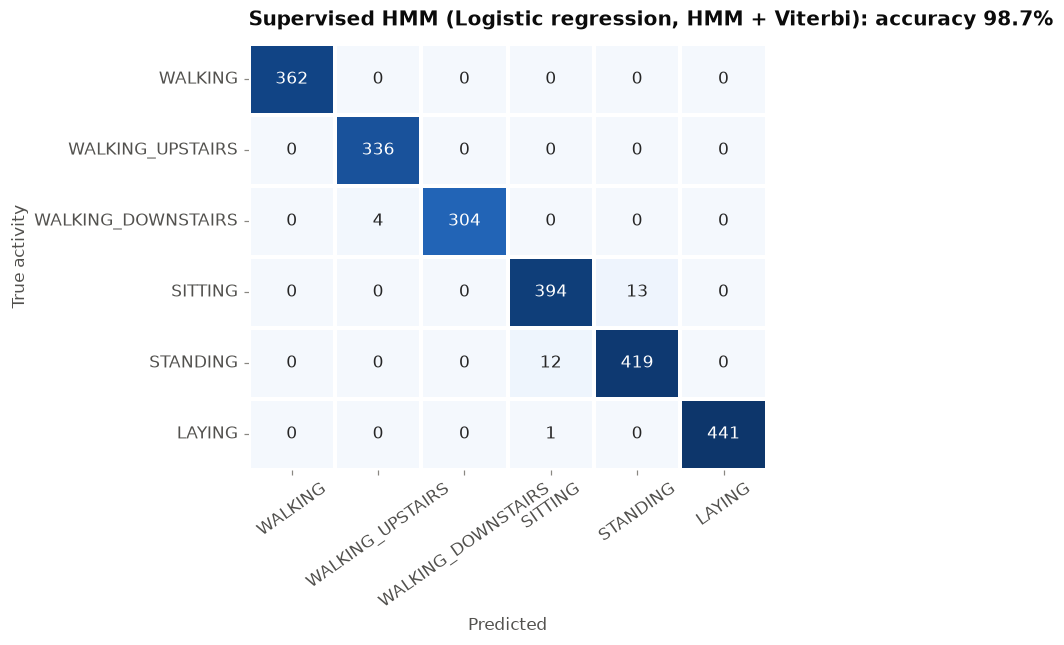

In [15]:
best_key = ("Logistic regression", "HMM + Viterbi")           # headline model: hybrid HMM decoded with Viterbi
best_pred = sup_preds[best_key]
best_acc = accuracy_score(y0_te, best_pred)
names6 = [ACT_MAP[i + 1] for i in range(6)]
cm2 = confusion_matrix(y0_te, best_pred, labels=range(6))
fig, ax = plt.subplots(figsize=(7.2, 6))
sns.heatmap(cm2, annot=True, fmt="d", cmap=SEQ_BLUE, cbar=False, linewidths=1.5, linecolor=SURFACE,
            xticklabels=names6, yticklabels=names6, ax=ax)
ax.set(title=f"Supervised HMM ({best_key[0]}, {best_key[1]}): accuracy {best_acc:.1%}", xlabel="Predicted", ylabel="True activity")
ax.tick_params(axis="x", rotation=35); ax.tick_params(axis="y", rotation=0)
save(fig, "har_confusion_supervised")

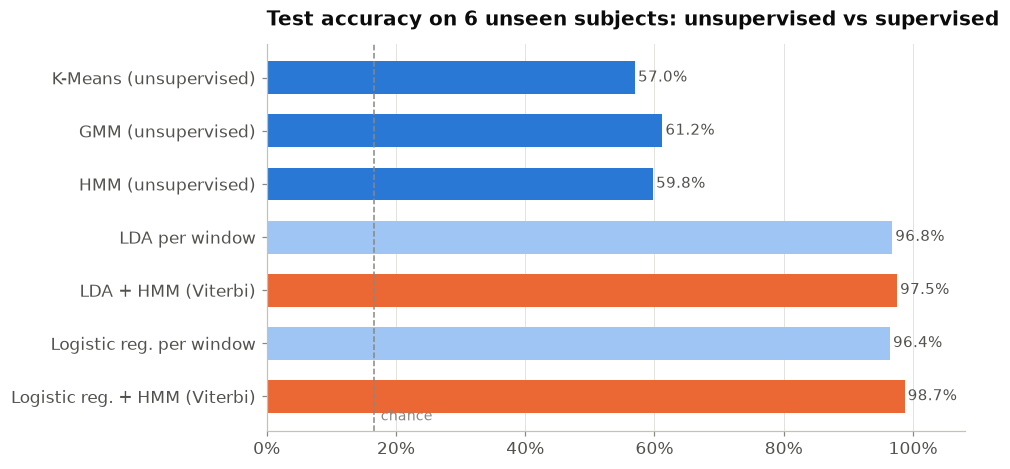

In [16]:
all_rows = [("K-Means (unsupervised)", cmp.loc[cmp.Model == "K-Means", "Test accuracy"].iloc[0]),
            ("GMM (unsupervised)", cmp.loc[cmp.Model == "Gaussian Mixture", "Test accuracy"].iloc[0]),
            ("HMM (unsupervised)", cmp.loc[cmp.Model == "Gaussian HMM (Viterbi)", "Test accuracy"].iloc[0])]
for (e, d), pred in sup_preds.items():
    if d != "HMM + forward–backward":
        label = ("LDA" if e.startswith("Gaussian") else "Logistic reg.") + (" per window" if d.startswith("per") else " + HMM (Viterbi)")
        all_rows.append((label, accuracy_score(y0_te, pred)))
ov = pd.DataFrame(all_rows, columns=["Approach", "Test accuracy"])
fig, ax = plt.subplots(figsize=(9, 4.4))
colors = [SERIES[0] if "unsup" in a else (SERIES[1] if "HMM" in a else "#9ec5f4") for a in ov.Approach]
ax.barh(ov.Approach[::-1], ov["Test accuracy"][::-1], color=colors[::-1], height=0.62)
for yv, v in enumerate(ov["Test accuracy"][::-1]):
    ax.text(v + 0.005, yv, f"{v:.1%}", va="center", fontsize=9.5, color=INK_2)
ax.axvline(1 / 6, color=MUTED, ls="--", lw=1); ax.text(1 / 6 + 0.01, -0.45, "chance", fontsize=9, color=MUTED)
ax.set(title="Test accuracy on 6 unseen subjects: unsupervised vs supervised", xlim=(0, 1.08))
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.grid(axis="y", visible=False)
save(fig, "har_overall_comparison")

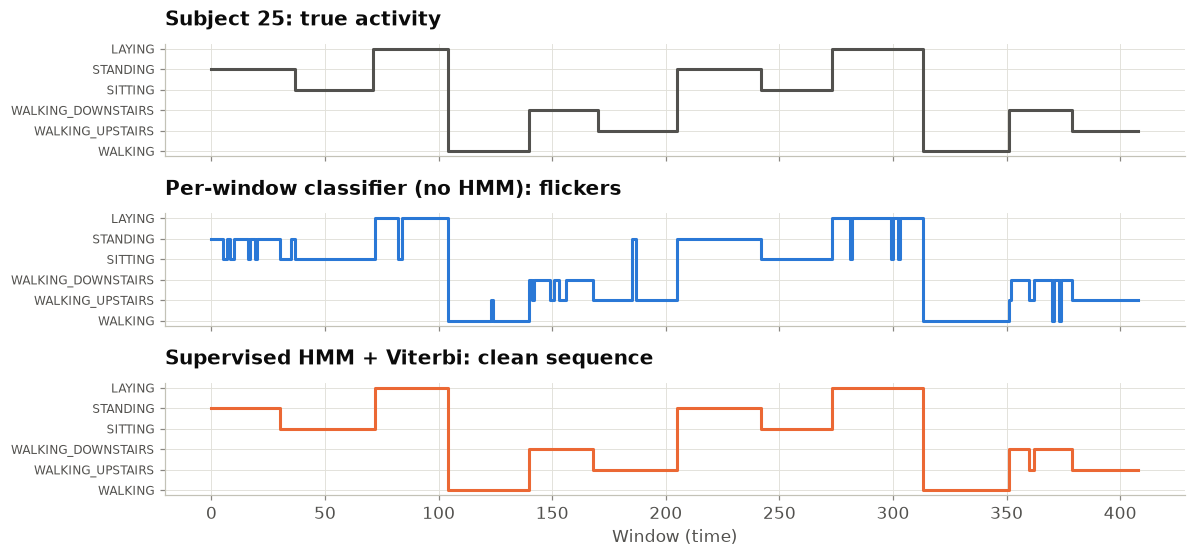

In [17]:
s0_mask = te_feat.subject.values == test_subj[0]
fig, axes = plt.subplots(3, 1, figsize=(11, 5.2), sharex=True, sharey=True)
for ax, (lab, title, col) in zip(axes, [(y0_te[s0_mask], f"Subject {test_subj[0]}: true activity", INK_2),
                                        (sup_preds[(best_key[0], "per window (no HMM)")][s0_mask], "Per-window classifier (no HMM): flickers", SERIES[0]),
                                        (best_pred[s0_mask], "Supervised HMM + Viterbi: clean sequence", SERIES[1])]):
    ax.step(range(s0_mask.sum()), lab, color=col, where="post")
    ax.set(title=title); ax.set_yticks(range(6), names6, fontsize=8)
axes[-1].set_xlabel("Window (time)")
save(fig, "har_supervised_timeline")

In [18]:
summary = {
    "n_windows": len(feat), "n_subjects": feat.subject.nunique(), "n_states": N,
    "train_subjects": int(len(train_subj)), "test_subjects": int(len(test_subj)),
    "train_loglik": float(best_ll), "test_accuracy": float(acc), "test_ari": float(ari),
    "manual_matches_hmmlearn_viterbi": bool(np.array_equal(path_manual, path_lib)),
    "max_forward_backward_diff": float(np.abs(gamma_manual - gamma_lib).max()),
    "state_to_activity": {int(k): ACT_MAP[v] for k, v in state_to_activity.items()},
    "transmat": model.transmat_.tolist(),
    "comparison": cmp.to_dict("records"),
    "supervised": sup.to_dict("records"),
    "supervised_best": {"emission": best_key[0], "decoding": best_key[1], "accuracy": float(best_acc)},
    "transmat_supervised": A_sup.tolist(),
}
save_json(summary, "har_hmm_summary")
pd.Series({k: v for k, v in summary.items() if not isinstance(v, (list, dict))})

n_windows                                 10299
n_subjects                                   30
n_states                                      6
train_subjects                               24
test_subjects                                 6
train_loglik                       84888.871096
test_accuracy                           0.59755
test_ari                               0.485123
manual_matches_hmmlearn_viterbi            True
max_forward_backward_diff                   0.0
dtype: object

**Interpretation**
1. Our hand-coded forward–backward and Viterbi match `hmmlearn` exactly (max posterior difference ~1e-10; identical
   decoded path), so the algorithms are implemented correctly, not just called from a library.
2. The unsupervised HMM — fit with **no activity labels** — labels unseen subjects correctly ≈60 % of the time
   (chance ≈17 %) once its 6 abstract states are matched to activity names (Hungarian algorithm, training data only).
3. **Laying** is recognised best (gravity points a different way). The main confusions are **Walking ↔ Walking upstairs**
   and **Sitting ↔ Standing**: these pairs produce very similar accelerometer readings from a waist-worn phone.
4. **HMM vs clustering:** K-Means and GMM, which ignore time, reach similar accuracy (0.57 / 0.61), but the HMM produces
   the most realistic sequences — the longest segments, i.e. the fewest spurious activity switches — because its
   transition matrix (diagonal 0.73–0.94) encodes that people keep doing the same activity for many windows.
5. **Supervised HMM (Section 7):** with labels for training, the 561 accelerometer + gyroscope features and Viterbi
   decoding, test accuracy rises to ≈97–99 %. Viterbi removes most isolated per-window mistakes, so the HMM beats
   the same classifier applied window by window, which shows the value of the Markov transition structure.
6. Remaining errors are mostly Sitting ↔ Standing, the hardest pair even with gyroscope data.